# FUT fBVOC emission source: which prescribed emissions for the main FUT run?

**Open decision (paper, `\ONHOLD` in `methods-claude.tex`):** which fixed-BVOC run is the reference for the FUT BVOC effect. This notebook puts the candidates side by side on the CO₂-fix (new-chain) runs, **2001–2014** (first 12 months dropped), so the choice can be made. Created 2026-11-06 (user request); it replaces `fut-fbvoc-emission-source.ipynb` (CTRL_PD vs CTRL_FUT only, retired to `analysis/_old/` 2026-11-06) and adds LCC_PD, the artefact correction and the Ghan maps.

| Source of the prescribed emissions | fBVOC run | BVOC contrast `LCC_FUT − fBVOC` measures |
|---|---|---|
| **CTRL_PD** (PD climate, CTRL land) | `LCC_FUT_fBVOCctrlPD` | land-cover change **+** climate/CO₂ emission response, both vs today's emissions |
| **CTRL_FUT** (FUT climate, CTRL land) | `LCC_FUT_fBVOCctrlFUT` | emission change from the **land-cover change** in the FUT climate (incl. vegetation-induced weather changes over the new forest) |
| **LCC_PD** (PD climate, LCC land) | `LCC_FUT_fBVOClccPD` | **climate/CO₂-driven** emission change on the expanded-forest land |
| *(no source)* `LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD` | — | same LCC_FUT setup, only the prescribed emissions differ (FUT − PD CTRL climatology) = row CTRL_PD − row CTRL_FUT; the artefact cancels, so no correction |
| LCC_FUT (own emissions, design A) | `LCC_FUT_fBVOClccFUT` | prescription artefact on LCC land only (row added automatically once processed; run starts ~7 Nov) |

Algebra (exact, per year and cell): (LCC_FUT − fBVOCctrlPD) = (LCC_FUT − fBVOCctrlFUT) + (fBVOCctrlFUT − fBVOCctrlPD).

**All contrasts below are artefact-corrected (design B, user 2026-11-06); the uncorrected versions, row by row next to the corrected ones, are in `diagnostics/fbvoc-prescription-artefact/how_big_artefact_is_FUT.ipynb`.**

**Artefact correction (design B):** art_FUT = `CTRL_FUT_fBVOCctrlFUT − CTRL_FUT` (prescribing a run's own emissions instead of computing them). Corrected BVOC effect = (LCC_FUT − fBVOC) + art_FUT; assumes art(LCC land) ≈ art(CTRL land), tested in PD (`diagnostics/fbvoc-prescription-artefact/how_big_artefact_is_PD.ipynb`).

**Caveats:** all fBVOC runs prescribe a 2001–2014 climatology (no interannual or weather coupling); all 19 MEGAN species are prescribed. Statistics: paired years (same nudged weather), mean ± 95 % t-interval across the 14 yearly means; descriptive, no correction for the many diagnostics. Inputs: `data/processed-data/postprocessing/<alias>_atm_<CLASS>_2001-2014.nc`. Outputs: `fut-fbvoc-emission-source-choice_outputs/`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm
from boreal_forest_expansion.plotting import palette as pal

set_default_style()
pd.set_option("display.width", 220, "display.max_rows", 300)
START_YEAR, END_YEAR = 2001, 2014
OUT = Path("fut-fbvoc-emission-source-choice_outputs")
FIGDIR, TABLES = OUT / "figures", OUT / "tables"
FIGDIR.mkdir(parents=True, exist_ok=True); TABLES.mkdir(parents=True, exist_ok=True)

LCC, CTRL = "LCC_FUT", "CTRL_FUT"
CANDIDATES = {"CTRL_PD": "LCC_FUT_fBVOCctrlPD", "CTRL_FUT": "LCC_FUT_fBVOCctrlFUT",
              "LCC_PD": "LCC_FUT_fBVOClccPD", "LCC_FUT": "LCC_FUT_fBVOClccFUT"}
ART = ("CTRL_FUT_fBVOCctrlFUT", CTRL)   # art_FUT
# keep only candidates whose processed files exist (LCC_FUT_fBVOClccFUT is not run yet)
CANDIDATES = {s: a for s, a in CANDIDATES.items()
              if all(fm.filename(a, c, START_YEAR, END_YEAR).exists() for c in ("BVOC", "SOA", "RADIATIVE"))}
# design B: corrected reference = fBVOC_source − CTRL_FUT_fBVOCctrlFUT + CTRL_FUT (fm.corrected_fbvoc),
# so LCC_FUT − reference = (LCC_FUT − fBVOC_source) + art_FUT, year by year
CORR_ROWS = {s: (LCC, fm.corrected_fbvoc("FUT", a[len("LCC_FUT_fBVOC"):])) for s, a in CANDIDATES.items()}
SRC_DIFF = ("LCC_FUT_fBVOCctrlFUT", "LCC_FUT_fBVOCctrlPD")   # prescribed emissions only (= row ctrlPD − row ctrlFUT); artefact cancels
LABEL = {r: f"source {s} (corrected)" for s, r in CORR_ROWS.items()}
LABEL[SRC_DIFF] = "ctrlFUT − ctrlPD emissions"
SHOWN = list(LABEL)   # corrected contrasts + emissions-only row, used in every section
COLORS = dict(zip(LABEL, pal.PALETTE_ORDER))   # palette order: teal, navy, plum, …

for alias in sorted({LCC, *CANDIDATES.values(), *ART}):
    for cls in ("BVOC", "SOA", "RADIATIVE"):
        p = fm.filename(alias, cls, START_YEAR, END_YEAR)
        print(f"{p.name:55s}", "✓" if p.exists() else "MISSING")
print("Candidates used:", list(CANDIDATES))

CTRL_FUT_atm_BVOC_2001-2014.nc                          ✓
CTRL_FUT_atm_SOA_2001-2014.nc                           ✓
CTRL_FUT_atm_RADIATIVE_2001-2014.nc                     ✓
CTRL_FUT_fBVOCctrlFUT_atm_BVOC_2001-2014.nc             ✓
CTRL_FUT_fBVOCctrlFUT_atm_SOA_2001-2014.nc              ✓
CTRL_FUT_fBVOCctrlFUT_atm_RADIATIVE_2001-2014.nc        ✓
LCC_FUT_atm_BVOC_2001-2014.nc                           ✓
LCC_FUT_atm_SOA_2001-2014.nc                            ✓
LCC_FUT_atm_RADIATIVE_2001-2014.nc                      ✓
LCC_FUT_fBVOCctrlFUT_atm_BVOC_2001-2014.nc              ✓
LCC_FUT_fBVOCctrlFUT_atm_SOA_2001-2014.nc               ✓
LCC_FUT_fBVOCctrlFUT_atm_RADIATIVE_2001-2014.nc         ✓
LCC_FUT_fBVOCctrlPD_atm_BVOC_2001-2014.nc               ✓
LCC_FUT_fBVOCctrlPD_atm_SOA_2001-2014.nc                ✓
LCC_FUT_fBVOCctrlPD_atm_RADIATIVE_2001-2014.nc          ✓
LCC_FUT_fBVOClccPD_atm_BVOC_2001-2014.nc                ✓
LCC_FUT_fBVOClccPD_atm_SOA_2001-2014.nc                 ✓
LCC_FUT_fBVOCl

## 1. Emissions: what each design takes away (Tg yr⁻¹)
Corrected `LCC_FUT − fBVOC_source` (+ art_FUT emissions, ≈ 0 on average: the climatology vs the run's own yearly emissions). Annual sum of monthly totals, mean over years; early 2001–2007, late 2008–2014. Last column (`ctrlFUT − ctrlPD emissions`): how different the two CTRL climatologies are. Isoprene and monoterpenes only (the other 17 prescribed species follow the same source).

In [2]:
rows = []
for c1, c2 in SHOWN:
    for region in ("modified cells", "unmodified land ≥45°N", "≥45°N"):
        for field in ("SFISOP_Tg", "SFMTERP_Tg"):
            d = fm.monthly_difference(c1, c2, field, region, start_year=START_YEAR, end_year=END_YEAR).sum("month")
            rows.append(dict(source=LABEL[(c1, c2)], region=region, field=field, mean=float(d.mean()),
                             ci95=float(fm.stats.t.ppf(0.975, d.sizes["year"] - 1) * d.std(ddof=1) / np.sqrt(d.sizes["year"])),
                             early=float(d.sel(year=slice(*fm.EARLY_YEARS)).mean()),
                             late=float(d.sel(year=slice(*fm.LATE_YEARS)).mean())))
emis = pd.DataFrame(rows)
emis.to_csv(TABLES / f"emissions_LCC_FUT_minus_fBVOC_{START_YEAR}_{END_YEAR}.csv", index=False)
emis.pivot_table(index=["region", "field"], columns="source", values="mean", sort=False).round(3)

source                            source CTRL_PD (corrected)  source CTRL_FUT (corrected)  source LCC_PD (corrected)  ctrlFUT − ctrlPD emissions
region                field                                                                                                                     
modified cells        SFISOP_Tg                        8.722                        0.362                      8.482                       8.360
                      SFMTERP_Tg                      17.497                       -0.119                     17.462                      17.616
unmodified land ≥45°N SFISOP_Tg                        5.523                        0.025                      5.477                       5.498
                      SFMTERP_Tg                       9.267                        0.026                      9.244                       9.241
≥45°N                 SFISOP_Tg                       14.246                        0.387                     13.959                      13.858
                      SFMTERP_Tg                      26.764                       -0.093                     26.706                      26.857

## 2. Radiative budget per design, artefact-corrected (W m⁻²)
Ghan terms (toa = dir (ARI) + cloud + rest (clear-clean)) for NET, regional means ≥45°N and modified cells. Corrected = (LCC_FUT − fBVOC) + art_FUT, year by year; `ctrlFUT − ctrlPD emissions` needs no correction (artefact cancels); art_FUT itself listed for reference. Mean ± 95 % CI across years.

In [3]:
ref = fm.open_class(CTRL, "RADIATIVE", START_YEAR, END_YEAR)
masks = fm.region_masks(ref)
REGIONS = ("≥45°N", "modified cells")

def regional_years(c1, c2, band, term):
    d = fm.yearly_difference(c1, c2, "RADIATIVE", f"{band}_{term}", START_YEAR, END_YEAR)
    return {r: fm.regional(d, ref, masks[r]) for r in REGIONS}

rows = []
for band in ("NET", "SW", "LW"):
    for term in fm.GHAN_TERMS:
        art = regional_years(*ART, band, term)
        for r in SHOWN:
            d = regional_years(*r, band, term)
            for region in REGIONS:
                rows += [dict(source=LABEL[r], kind="corrected" if r != SRC_DIFF else "no correction needed", region=region,
                              band=band, term=term, year=int(y), value=float(v)) for y, v in zip(d[region]["year"].values, d[region].values)]
        for region in REGIONS:
            rows += [dict(source="art_FUT", kind="artefact", region=region, band=band, term=term, year=int(y), value=float(v))
                     for y, v in zip(art[region]["year"].values, art[region].values)]
budget = pd.DataFrame(rows)
g = budget.pivot_table(index=["source", "kind", "region", "band", "year"], columns="term", values="value")
print(f"Closure: max |dir + cloud + rest − toa| = {(g['dir'] + g['cloud'] + g['rest'] - g['toa']).abs().max():.1e} W m-2")
summary = fm.summarize_years(budget, ["source", "kind", "region", "band", "term"])
summary.to_csv(TABLES / f"radiative_budget_by_source_{START_YEAR}_{END_YEAR}.csv", index=False)
net = summary[summary.band == "NET"].copy()
net["mean ± ci95"] = net["mean"].map("{:+.3f}".format) + " ± " + net["ci95"].map("{:.3f}".format)
net.pivot_table(index=["region", "kind", "source"], columns="term", values="mean ± ci95", aggfunc="first", sort=False)

Closure: max |dir + cloud + rest − toa| = 1.4e-07 W m-2


term                                                                      cloud             dir            rest             toa
region         kind                 source                                                                                     
modified cells artefact             art_FUT                      -0.104 ± 0.047  +0.001 ± 0.006  +0.003 ± 0.013  -0.100 ± 0.057
               no correction needed ctrlFUT − ctrlPD emissions   -1.172 ± 0.041  -0.055 ± 0.012  +0.086 ± 0.016  -1.141 ± 0.033
               corrected            source CTRL_FUT (corrected)  -0.047 ± 0.046  -0.001 ± 0.014  -0.017 ± 0.012  -0.065 ± 0.059
                                    source CTRL_PD (corrected)   -1.218 ± 0.060  -0.056 ± 0.013  +0.068 ± 0.016  -1.206 ± 0.067
                                    source LCC_PD (corrected)    -1.196 ± 0.052  -0.059 ± 0.013  +0.074 ± 0.013  -1.181 ± 0.058
≥45°N          artefact             art_FUT                      -0.084 ± 0.042  -0.000 ± 0.006  -0.003 ± 0.013  -0.087 ± 0.046
               no correction needed ctrlFUT − ctrlPD emissions   -1.052 ± 0.024  -0.031 ± 0.013  +0.144 ± 0.013  -0.939 ± 0.023
               corrected            source CTRL_FUT (corrected)  -0.039 ± 0.032  -0.003 ± 0.016  -0.015 ± 0.012  -0.056 ± 0.045
                                    source CTRL_PD (corrected)   -1.090 ± 0.040  -0.034 ± 0.016  +0.129 ± 0.014  -0.995 ± 0.042
                                    source LCC_PD (corrected)    -1.078 ± 0.043  -0.038 ± 0.015  +0.130 ± 0.014  -0.986 ± 0.046

## 3. BVOC → SOA → cloud maps (artefact-corrected)
Rows: corrected `LCC_FUT − fBVOC_source` per source (`…_corr` = `LCC_FUT − (fBVOC_source − CTRL_FUT_fBVOCctrlFUT + CTRL_FUT)`, derived fields per real pair), then `LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD` (emissions only, no correction needed), last row art_FUT (the correction itself). Once `LCC_FUT_fBVOClccFUT` (design A) exists, its corrected row is art_CTRL − art_LCC (test of the design-B assumption). Each panel has its own colour scale; hatched = not significant (paired yearly t-test, FDR). Uncorrected vs corrected side by side: `diagnostics/fbvoc-prescription-artefact/how_big_artefact_is_FUT.ipynb`.

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Saved fut-fbvoc-emission-source-choice_outputs/figures/contrast_grid_context_FUT-fBVOC-source-choice_2001_2014.png


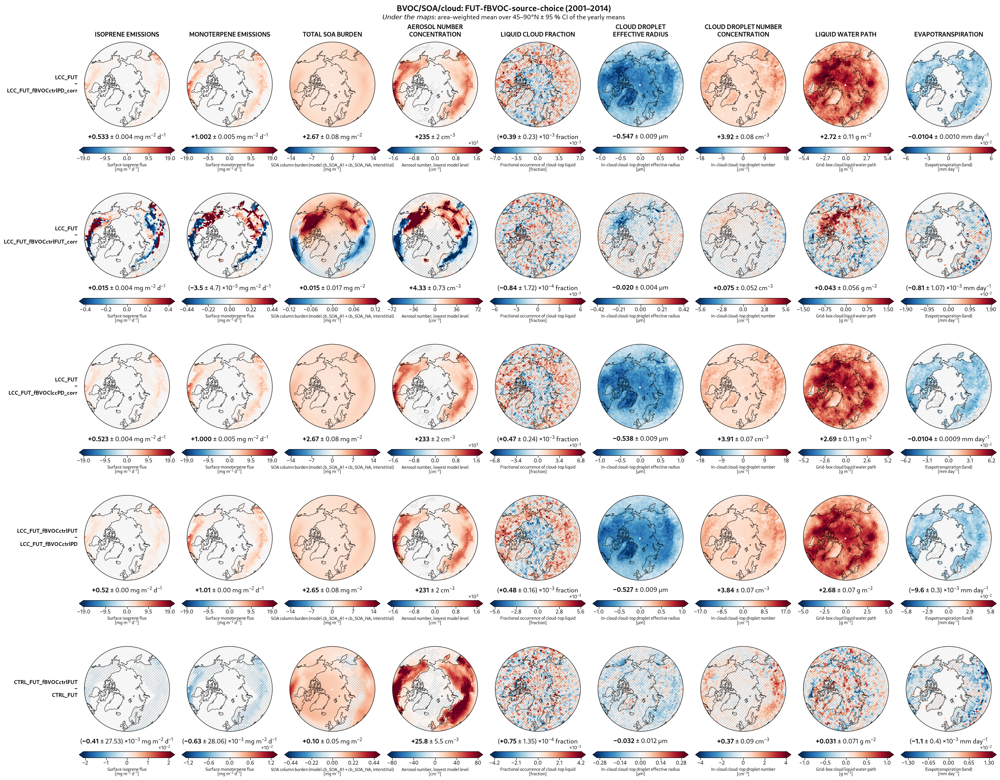

In [4]:
fig, axes = fm.make_contrast_grid_figure("FUT-fBVOC-source-choice", fm.CONTEXT_PANELS, "context", rows=SHOWN + [ART],
                                         start_year=START_YEAR, end_year=END_YEAR, figdir=FIGDIR)
plt.show(); plt.close(fig)

## 4. Ghan decomposition maps, annual (one figure per contrast and band)
total = ARI + cloud + clear-clean, one shared scale per figure; NET, SW, LW. Order: corrected per source (`…_corr`), `ctrlFUT − ctrlPD emissions`, art_FUT. Files `FUT_ghan_<case1>-<case2>_<band>_2001_2014.png` in `figures/ghan/`.

Ghan closure FUT LCC-fBVOC NET ANN: max |sum of terms - total| = 9.7e-06 W m-2


findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_LCC-fBVOCctrlPD_corr_NET_2001_2014.png


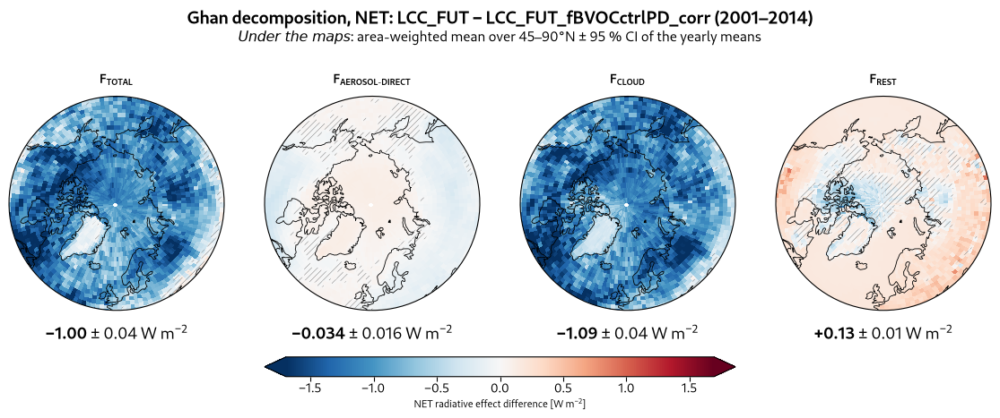

Ghan closure FUT LCC-fBVOC SW ANN: max |sum of terms - total| = 1.9e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_LCC-fBVOCctrlPD_corr_SW_2001_2014.png


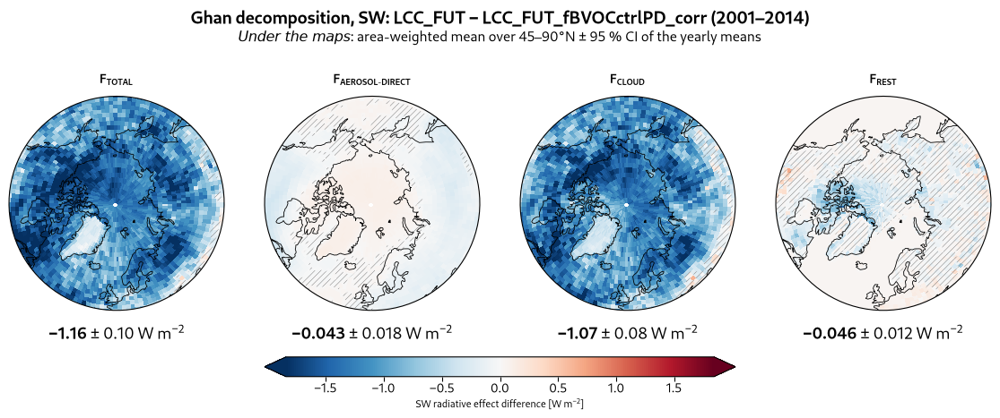

Ghan closure FUT LCC-fBVOC LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_LCC-fBVOCctrlPD_corr_LW_2001_2014.png


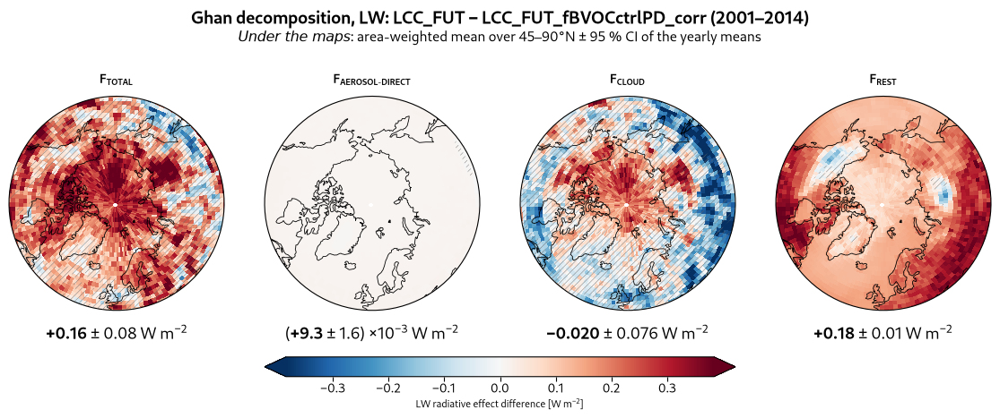

Ghan closure FUT LCC-fBVOC NET ANN: max |sum of terms - total| = 1.0e-05 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_LCC-fBVOCctrlFUT_corr_NET_2001_2014.png


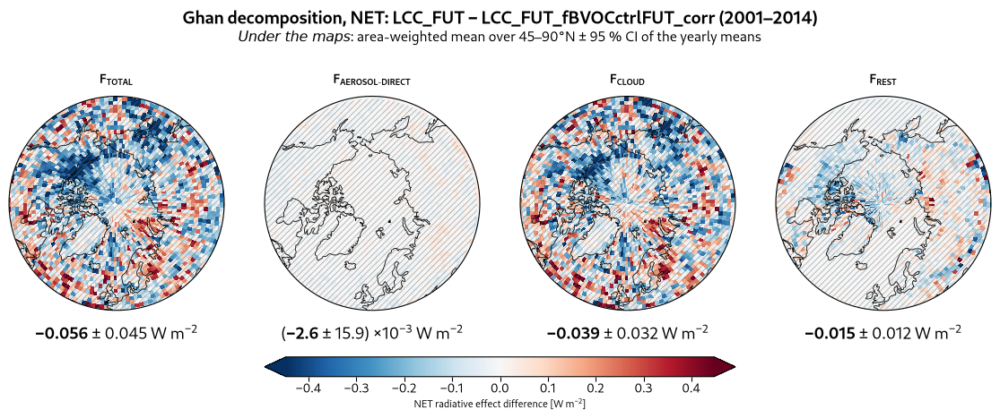

Ghan closure FUT LCC-fBVOC SW ANN: max |sum of terms - total| = 2.6e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_LCC-fBVOCctrlFUT_corr_SW_2001_2014.png


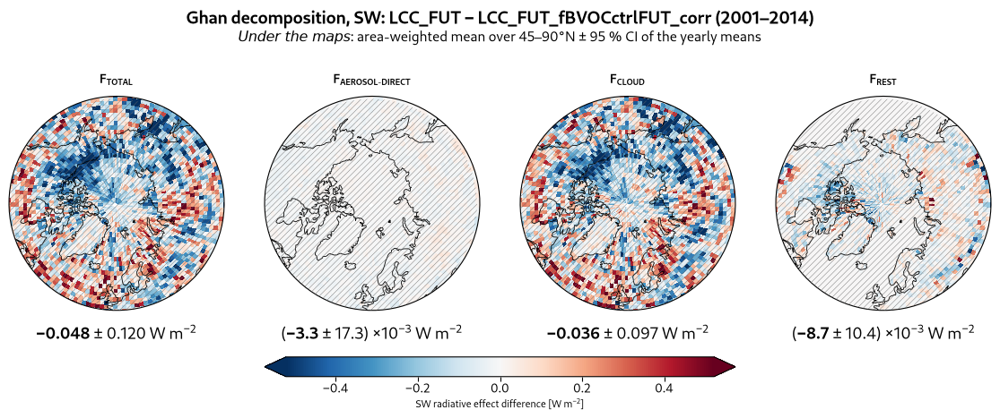

Ghan closure FUT LCC-fBVOC LW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_LCC-fBVOCctrlFUT_corr_LW_2001_2014.png


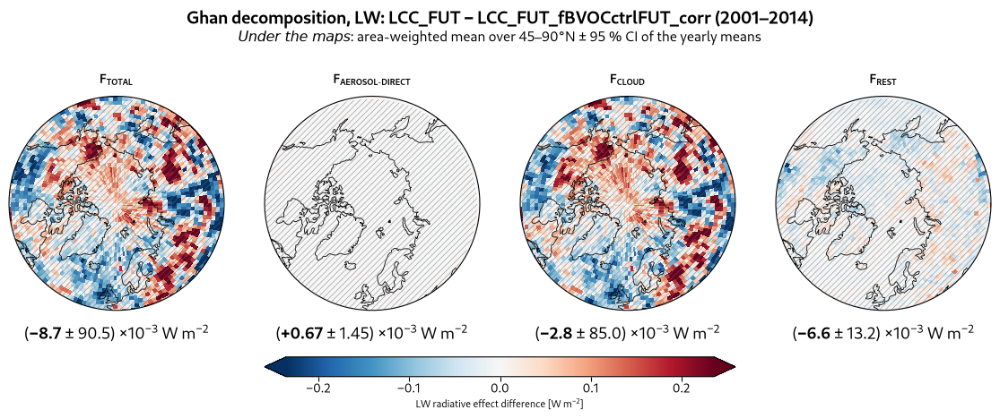

Ghan closure FUT LCC-fBVOC NET ANN: max |sum of terms - total| = 9.9e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_LCC-fBVOClccPD_corr_NET_2001_2014.png


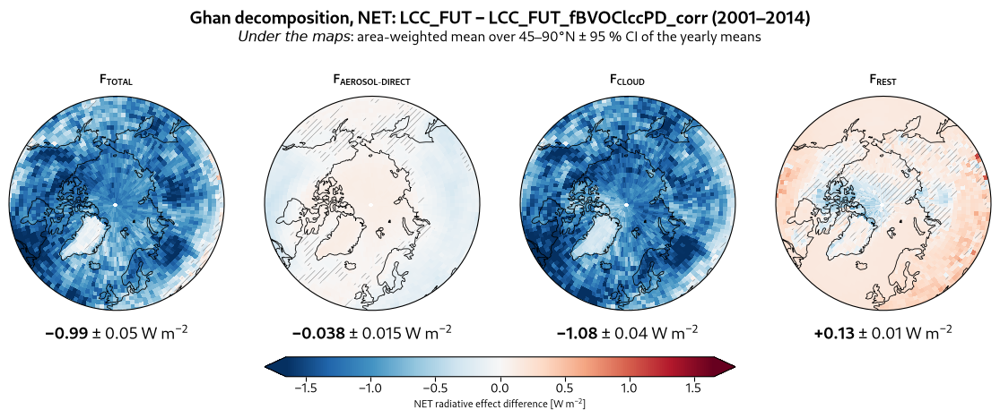

Ghan closure FUT LCC-fBVOC SW ANN: max |sum of terms - total| = 1.9e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_LCC-fBVOClccPD_corr_SW_2001_2014.png


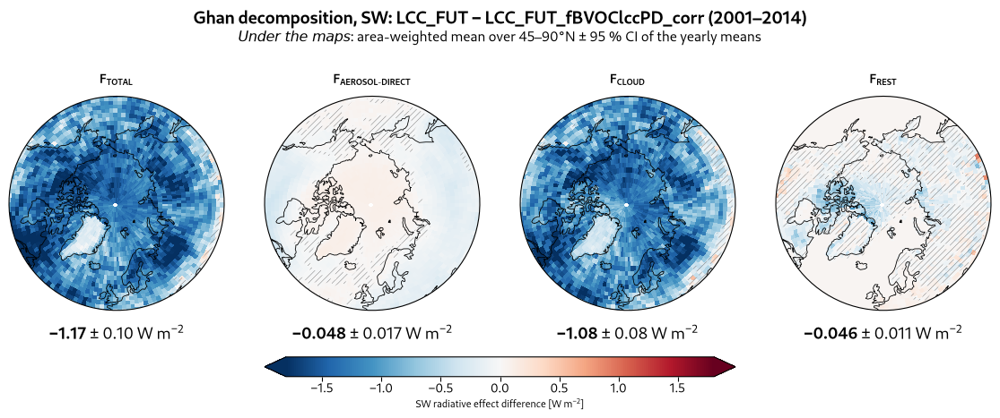

Ghan closure FUT LCC-fBVOC LW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_LCC-fBVOClccPD_corr_LW_2001_2014.png


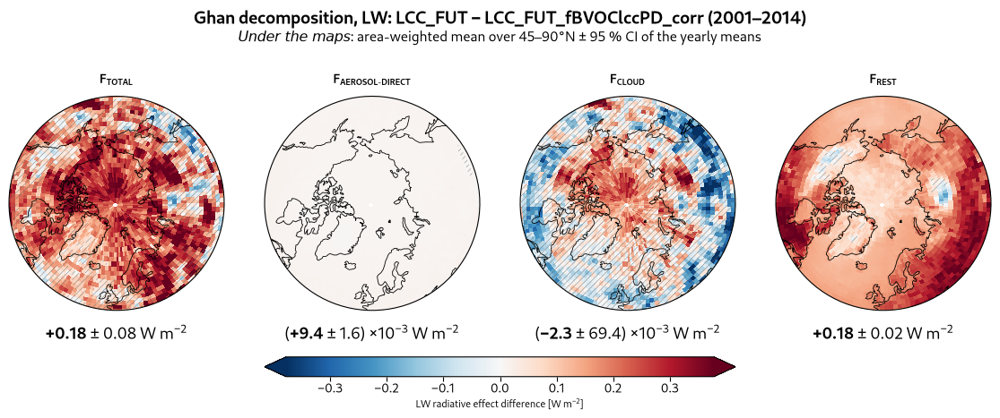

Ghan closure FUT LCC-fBVOC NET ANN: max |sum of terms - total| = 7.1e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_fBVOCctrlFUT-fBVOCctrlPD_NET_2001_2014.png


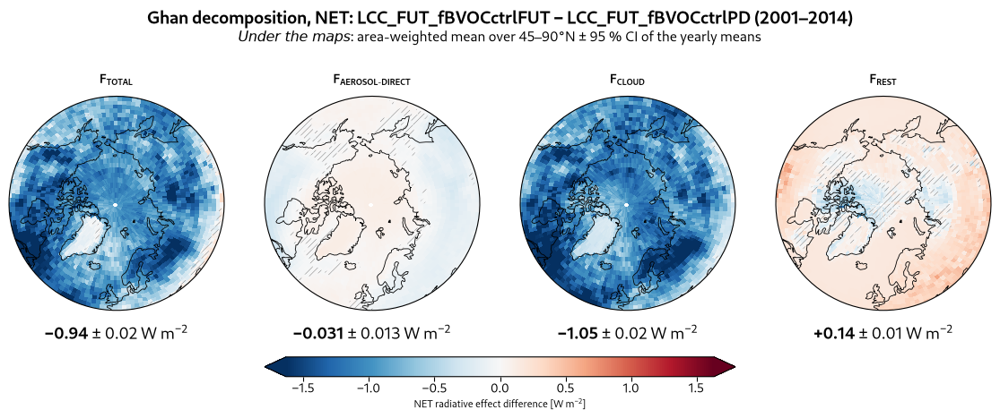

Ghan closure FUT LCC-fBVOC SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_fBVOCctrlFUT-fBVOCctrlPD_SW_2001_2014.png


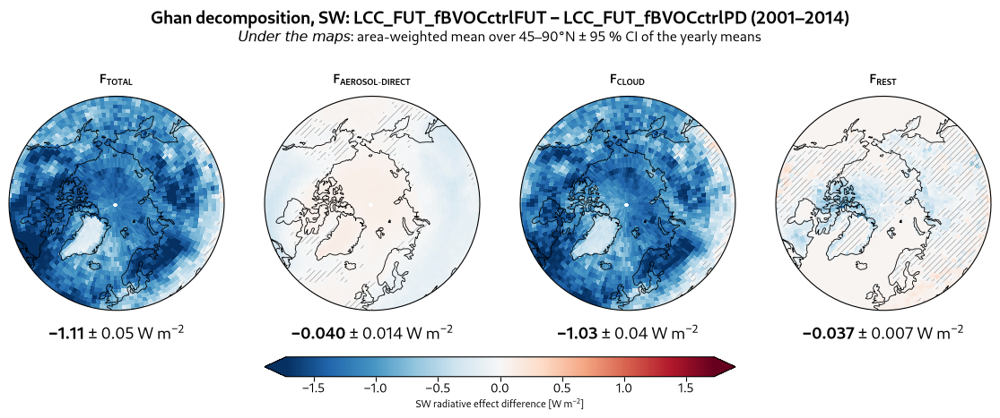

Ghan closure FUT LCC-fBVOC LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_fBVOCctrlFUT-fBVOCctrlPD_LW_2001_2014.png


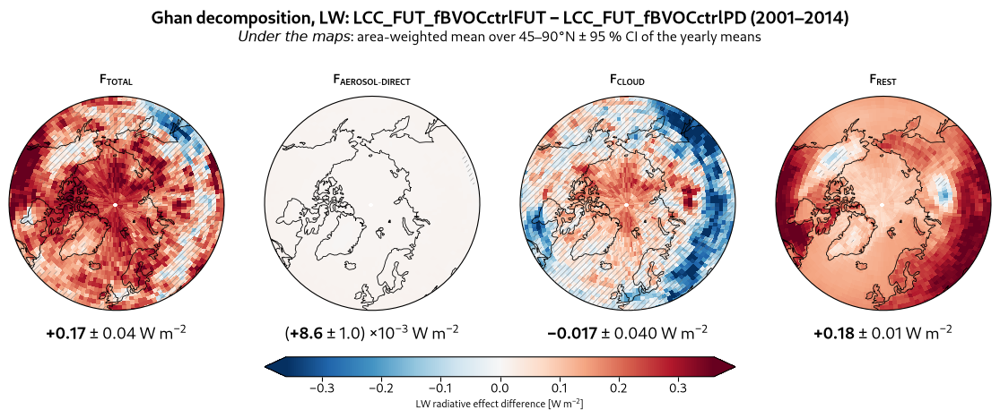

Ghan closure FUT LCC-fBVOC NET ANN: max |sum of terms - total| = 7.1e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_CTRL_FUT_fBVOCctrlFUT-CTRL_FUT_NET_2001_2014.png


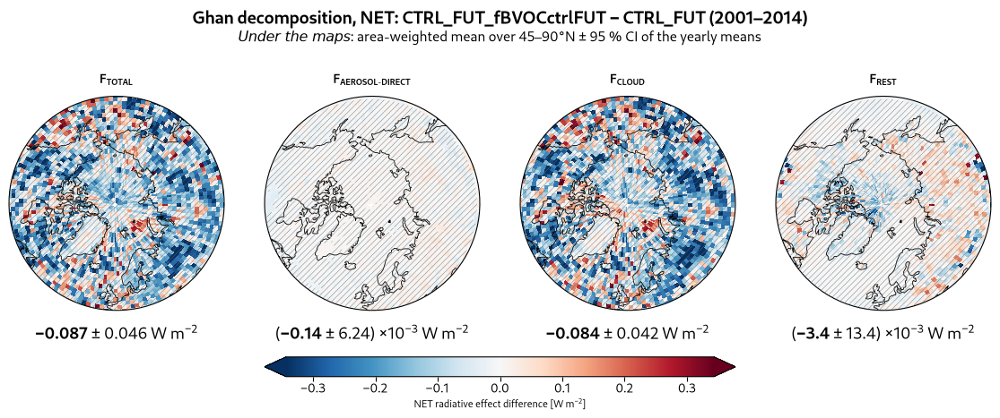

Ghan closure FUT LCC-fBVOC SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_CTRL_FUT_fBVOCctrlFUT-CTRL_FUT_SW_2001_2014.png


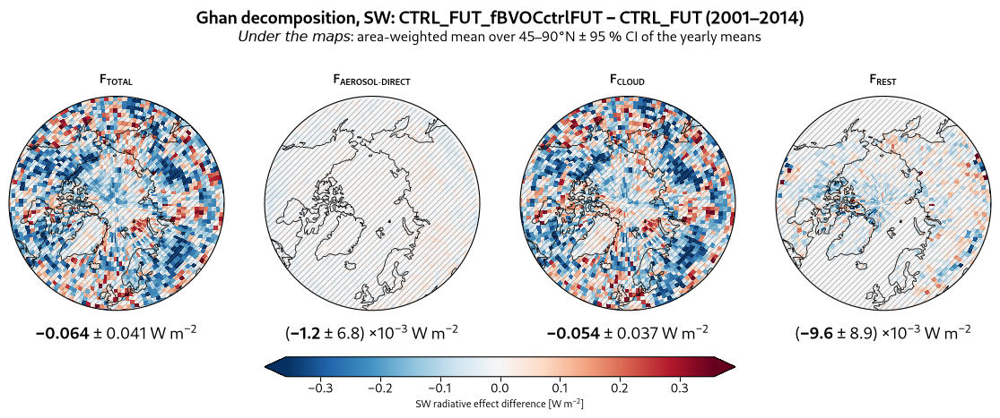

Ghan closure FUT LCC-fBVOC LW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved fut-fbvoc-emission-source-choice_outputs/figures/ghan/FUT_ghan_CTRL_FUT_fBVOCctrlFUT-CTRL_FUT_LW_2001_2014.png


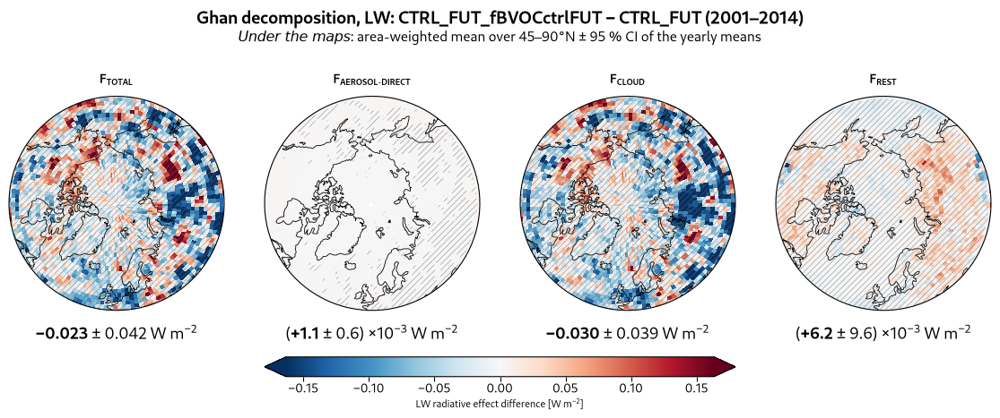

In [5]:
GHANDIR = FIGDIR / "ghan"; GHANDIR.mkdir(exist_ok=True)
for c1, c2 in SHOWN + [ART]:
    pairs = {"lcc": c1, "fbvoc": c2, "ctrl": CTRL}
    for band in ("NET", "SW", "LW"):
        fig, axes = fm.make_ghan_figure("FUT", "bvoc", band, pairs=pairs, start_year=START_YEAR, end_year=END_YEAR, figdir=GHANDIR)
        plt.show(); plt.close(fig)

## 5. Seasonal chain: emissions → SOA → aerosol → cloud → SW
Monthly regional differences, artefact-corrected, mean ± 95 % CI across years; grey dashed = art_FUT.

findfont: Failed to find font weight semibold, now using 700.


Saved fut-fbvoc-emission-source-choice_outputs/figures/fut_fbvoc_source_choice_seasonal_chain_2001_2014.png


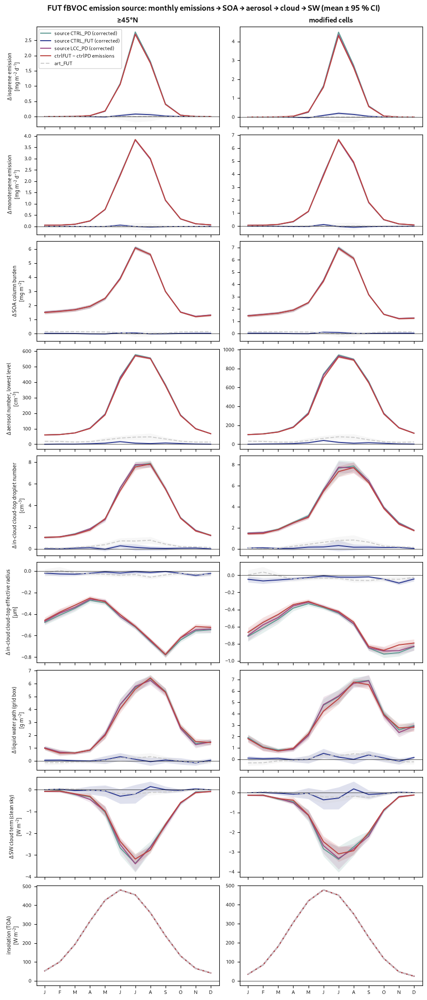

In [6]:
lines = {LABEL[r]: (*r, COLORS[r], "-") for r in SHOWN}
lines["art_FUT"] = (*ART, pal.LIGHT_GREY if hasattr(pal, "LIGHT_GREY") else "#CCCCCC", "--")
fig, axes = fm.make_monthly_chain_figure(
    ["SFISOP", "SFMTERP", "cbSOA", "N_AER", "ACTNL_incld", "ACTREL_incld", "TGCLDLWP", "SW_cloud"],
    ["≥45°N", "modified cells"], lines, "fut_fbvoc_source_choice_seasonal_chain",
    "FUT fBVOC emission source: monthly emissions → SOA → aerosol → cloud → SW (mean ± 95 % CI)",
    context="SOLIN", start_year=START_YEAR, end_year=END_YEAR, figdir=FIGDIR)
plt.show(); plt.close(fig)

## 5. Reading for the decision (2001–2014, written 2026-11-06 from the outputs above)

**1. What each source takes away (§1, ≥45°N, Tg yr⁻¹).**

| Source | isoprene | monoterpenes | = mostly |
|---|---|---|---|
| CTRL_PD | +14.26 | +26.78 | climate/CO₂ response (FUT − PD) |
| LCC_PD | +13.97 | +26.72 | climate/CO₂ response on LCC land |
| CTRL_FUT | **+0.40** | **−0.08** | land-cover change only |

With either PD source, ~97–100 % of the emission change is the future climate/CO₂ response, not the forest expansion. The difference between the CTRL_PD and LCC_PD sources (+0.29 Tg isoprene, +0.06 monoterpenes) is the forest-expansion emission change under PD climate; CTRL_FUT gives it under FUT climate (+0.40 / −0.08).

**2. Net TOA radiation (§2, NET, mean ± 95 % CI over 14 years, W m⁻²).**

| | ≥45°N uncorrected | ≥45°N corrected | modified cells corrected |
|---|---|---|---|
| source CTRL_PD | −0.91 ± 0.05 | −1.00 ± 0.04 | −1.21 ± 0.07 |
| source LCC_PD | −0.90 ± 0.06 | −0.99 ± 0.05 | −1.18 ± 0.06 |
| source CTRL_FUT | +0.03 ± 0.04 | **−0.06 ± 0.05** | −0.07 ± 0.06 |
| art_FUT | | −0.09 ± 0.05 | −0.10 ± 0.06 |

- The PD-source contrasts are large, significant, and almost all cloud term (≥45°N cloud −1.09 corrected); the direct (ARI) term is small (−0.03) and clear-clean slightly positive (+0.13).
- The CTRL_FUT-source contrast, the forest-expansion-only BVOC effect, is **not distinguishable from zero** uncorrected, and its correction (art_FUT) is **as large as the signal itself**: the corrected value (−0.06 ± 0.05 ≥45°N) depends on the assumption art(LCC land) ≈ art(CTRL land).
- Sources CTRL_PD and LCC_PD give nearly the same answer (difference ≈ 0.01 W m⁻²): the land on which the PD emissions were computed hardly matters next to the PD→FUT climate change of the emissions.

**3. What this means for the choice (b).**
- If the paper's FUT question is *"what does the forest expansion's BVOC change do in a future climate?"*, the matching reference is **CTRL_FUT** (only that contrast isolates the land-cover change). Its answer is "small, ≈ −0.06 W m⁻² ≥45°N, comparable to the prescription artefact".
- **CTRL_PD / LCC_PD** sources answer a different question (*the effect of the future climate/CO₂-driven BVOC increase*, ≈ −1 W m⁻² ≥45°N). They are not forest-expansion effects and must not be labelled as such (CLAUDE.md: never call BVOC_FUT forest-expansion-only).
- Because the CTRL_FUT signal is the size of art_FUT, **LCC_FUT_fBVOClccFUT (design A, running from ~7 Nov)** is the key check: it measures the artefact on LCC land directly. Rerun this notebook when it is processed (the row is added automatically).
- The decision itself stays with the user (`\ONHOLD` in `methods-claude.tex`).

**Caveats.** 2001–2014 only (2015–2025 extensions running); prescribed climatologies lack interannual variability; §1/§4 and the uncorrected §3 rows are not artefact-corrected; p-values descriptive.
